# ACC_Modeling — Stage 3: 4-Wheel Contact-Patch & Suspension Physics Modeling (No SINDy)
**Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya (`R8_A`)**

This notebook implements **Stage 3** using **first-principles vehicle dynamics and calibrated black-box parameters** (no SINDy):
1. **Locked Calibrated Constants** (`vehicle.yaml` & `r8_A.yaml`): Dry mass `1161.2 kg` (identified from `2L.csv` vs. `110L.csv`), wheelbase `2.70 m`, track widths `1.67 / 1.65 m`, CG height `0.42 m`, calibrated ARB roll stiffness distribution (`[4, 2]`), spring wheel rates (`153 / 163 kN/m`), calibrated aero downforce ($C_L$ at `wing=5`), and steering ratio (`16.0`).
2. **4-Corner Normal Load $F_{z,i}(t)$**: Pitch + ARB-distributed roll transfer + $v^2$ downforce, cross-validated against `SUS_TRAVEL_*` + `BUMPSTOP_FORCE_*` telemetry.
3. **4-Wheel Pacejka Tire & Yaw Balance**: Nonlinear least squares (`scipy.optimize.least_squares`) fits only the unknown tire-road Magic Formula parameters ($\mu_0, B, C, E, \gamma_z$), yaw inertia $I_z$, and lateral compliance $k_{v_y}$ on `data/training_Barcelona_GT3.csv`, then validates out-of-sample on `data/verification_Barcelona_GT3.csv` (Full Lap + `T3`, `T4`, `T5`, `T13–T14–T15`).

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from src import (
    load_config,
    load_motec_csv,
    curate_telemetry,
    run_stage3_pipeline,
    plot_residual_distribution,
)

print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/ACC_Modeling


## 1. Load & Curate 20 Hz Training / Verification Telemetry

In [2]:
cfg = load_config("configs/experiments/stage3_wheel_corner/barcelona__audi_r8_gt3_evo2__r8_A.yaml")
out_dir = Path("outputs") / cfg.experiment_name
out_dir.mkdir(parents=True, exist_ok=True)

stage3_cols = [
    "Time", "ROTY", "STEERANGLE", "SPEED", "G_LAT", "G_LON", "THROTTLE", "BRAKE",
    "SUS_TRAVEL_LF", "SUS_TRAVEL_RF", "SUS_TRAVEL_LR", "SUS_TRAVEL_RR",
    "WHEEL_SPEED_LF", "WHEEL_SPEED_RF", "WHEEL_SPEED_LR", "WHEEL_SPEED_RR",
    "BUMPSTOP_FORCE_LF", "BUMPSTOP_FORCE_RF", "BUMPSTOP_FORCE_LR", "BUMPSTOP_FORCE_RR",
    "TYRE_PRESS_LF", "TYRE_PRESS_RF", "TYRE_PRESS_LR", "TYRE_PRESS_RR",
    "TYRE_TAIR_LF", "TYRE_TAIR_RF", "TYRE_TAIR_LR", "TYRE_TAIR_RR",
]

raw_tr, m_tr = load_motec_csv(cfg.data.clean_csv, channels=stage3_cols)
df_tr = curate_telemetry(raw_tr, m_tr, cfg.curation, trim_mode=cfg.data.clean_trim_mode, speed_threshold_kmh=cfg.data.clean_speed_threshold_kmh)

raw_va, m_va = load_motec_csv(cfg.data.race_csv, channels=stage3_cols)
df_va = curate_telemetry(raw_va, m_va, cfg.curation, trim_mode=cfg.data.race_trim_mode, speed_threshold_kmh=cfg.data.clean_speed_threshold_kmh)

print(f"Training rows: {len(df_tr)} | Verification rows: {len(df_va)} | Calibrated dry mass: {cfg.car.mass_kg} kg")

INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 2130 -> 2130 rows)


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 2129 -> 2129 rows)


Training rows: 2130 | Verification rows: 2129 | Calibrated dry mass: 1161.2 kg


## 2. Fit Stage 3 4-Wheel Physics Model & Cross-Validate Normal Loads

In [3]:
model, train_res, ver_res = run_stage3_pipeline(cfg, df_tr, df_va, fuel_liters=2.0)
model.save_json(Path("models") / f"{cfg.experiment_name}.json")

print("Identified Stage 3 Tire & Inertia Parameters:")
for k, v in model.params.to_dict().items():
    print(f"  {k:18s}: {v}")

print(f"\nTraining     -> ay R^2 = {train_res.eval_ay.r2:.4f} | r_{{k+1}} R^2 = {train_res.eval_r_next.r2:.4f}, RMSE = {train_res.eval_r_next.rmse:.4f} rad/s")
print(f"Verification -> ay R^2 = {ver_res.eval_ay.r2:.4f} | r_{{k+1}} R^2 = {ver_res.eval_r_next.r2:.4f}, RMSE = {ver_res.eval_r_next.rmse:.4f} rad/s")

Identified Stage 3 Tire & Inertia Parameters:
  mu0               : 1.29576
  pacejka_b         : 6.68304
  pacejka_c         : 1.72853
  pacejka_e         : -2.0
  load_sensitivity  : 0.33902
  iz_kg_m2          : 3500.0
  vy_compliance_s   : -0.19241

Training     -> ay R^2 = 0.9611 | r_{k+1} R^2 = 0.9876, RMSE = 0.0376 rad/s
Verification -> ay R^2 = 0.9334 | r_{k+1} R^2 = 0.9845, RMSE = 0.0432 rad/s


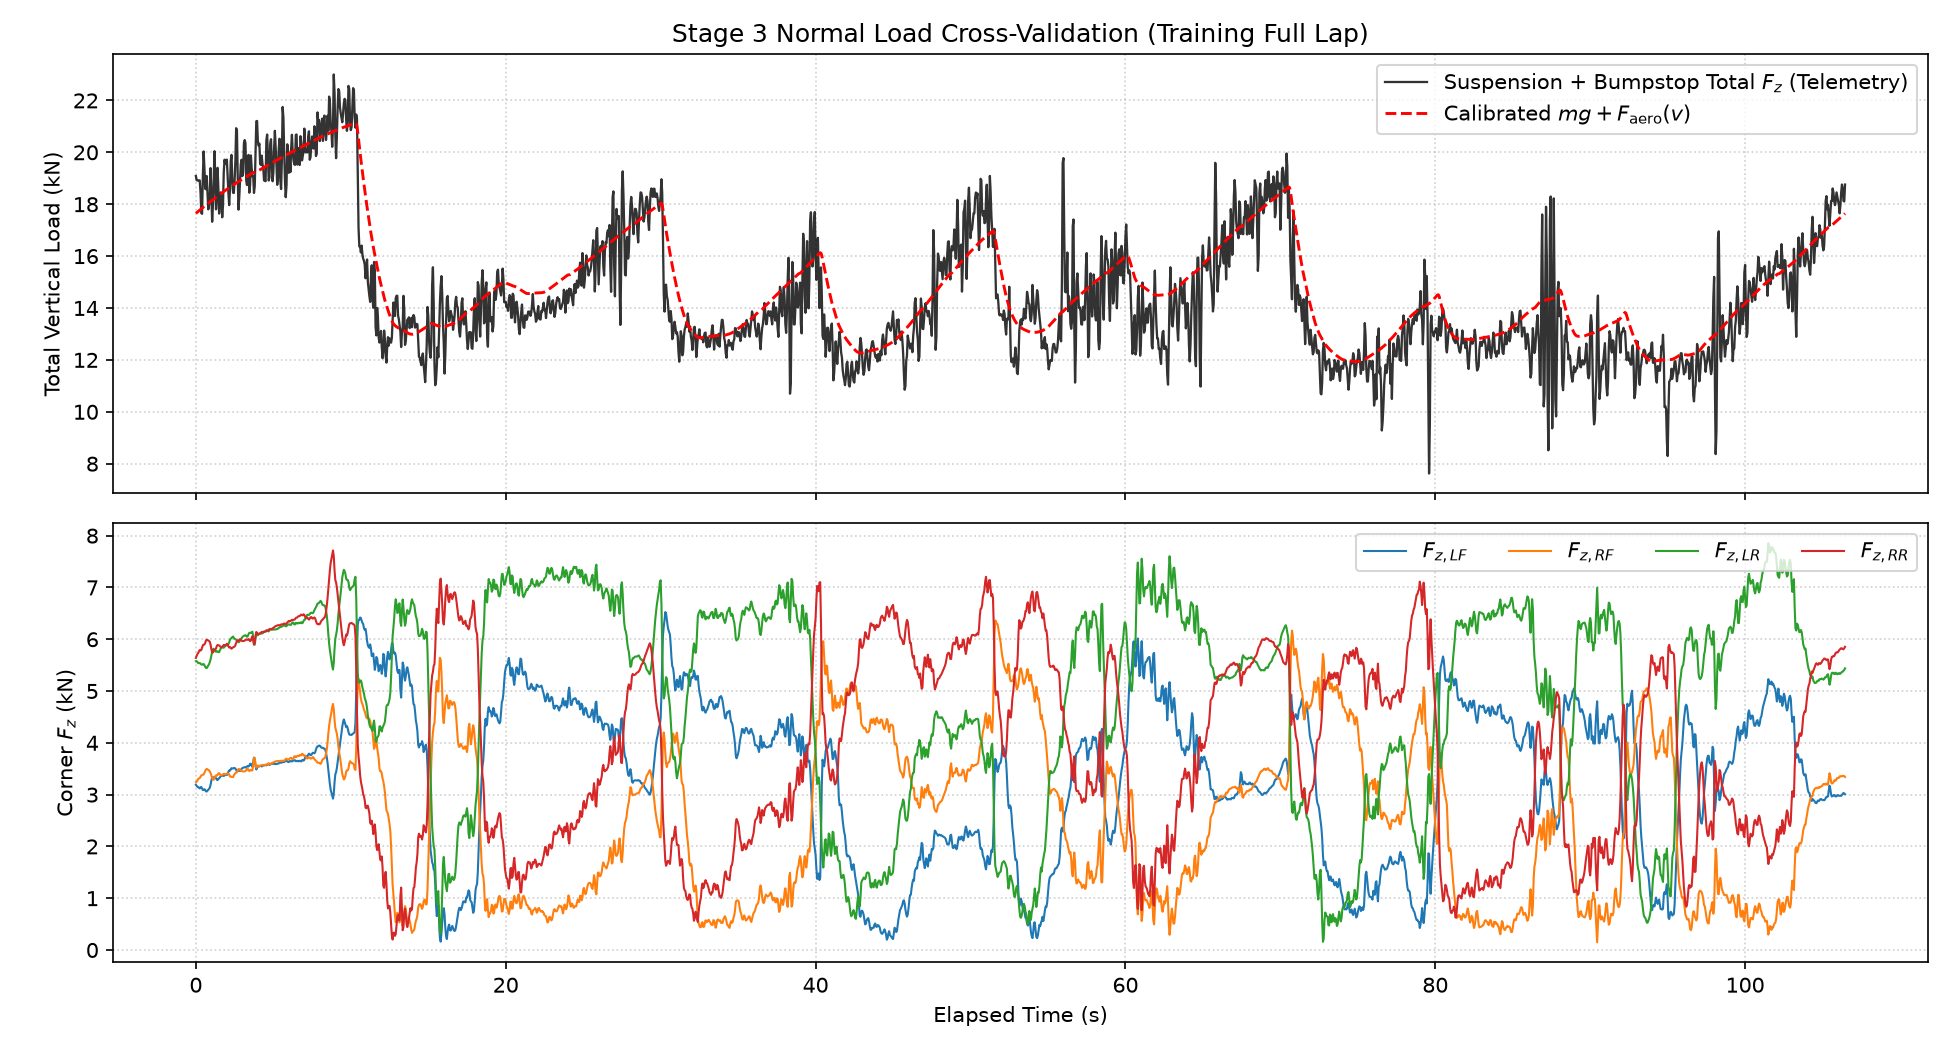

In [4]:
# Plot 1: Vertical Normal Load Cross-Validation (Aero+Static vs Suspension+Bumpstop)
t_tr = df_tr["Time"].to_numpy() - float(df_tr["Time"].iloc[0])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax1.plot(t_tr, train_res.fz_susp_total / 1000.0, "k-", lw=1.1, alpha=0.8, label="Suspension + Bumpstop Total $F_z$ (Telemetry)")
ax1.plot(t_tr, train_res.fz_aero_static_total / 1000.0, "r--", lw=1.4, label="Calibrated $mg + F_{\\mathrm{aero}}(v)$")
ax1.set_ylabel("Total Vertical Load (kN)")
ax1.set_title("Stage 3 Normal Load Cross-Validation (Training Full Lap)")
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend(loc="upper right")

for c, col in [("LF", "#1f77b4"), ("RF", "#ff7f0e"), ("LR", "#2ca02c"), ("RR", "#d62728")]:
    ax2.plot(t_tr, train_res.fz_corners[c] / 1000.0, lw=1.0, color=col, label=f"$F_{{z,{c}}}$")
ax2.set_xlabel("Elapsed Time (s)")
ax2.set_ylabel("Corner $F_z$ (kN)")
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend(loc="upper right", ncol=4)
fig.tight_layout()
fz_plot = out_dir / "normal_load_cross_validation.png"
fig.savefig(fz_plot, dpi=150)
plt.close(fig)
display(Image(filename=str(fz_plot)))

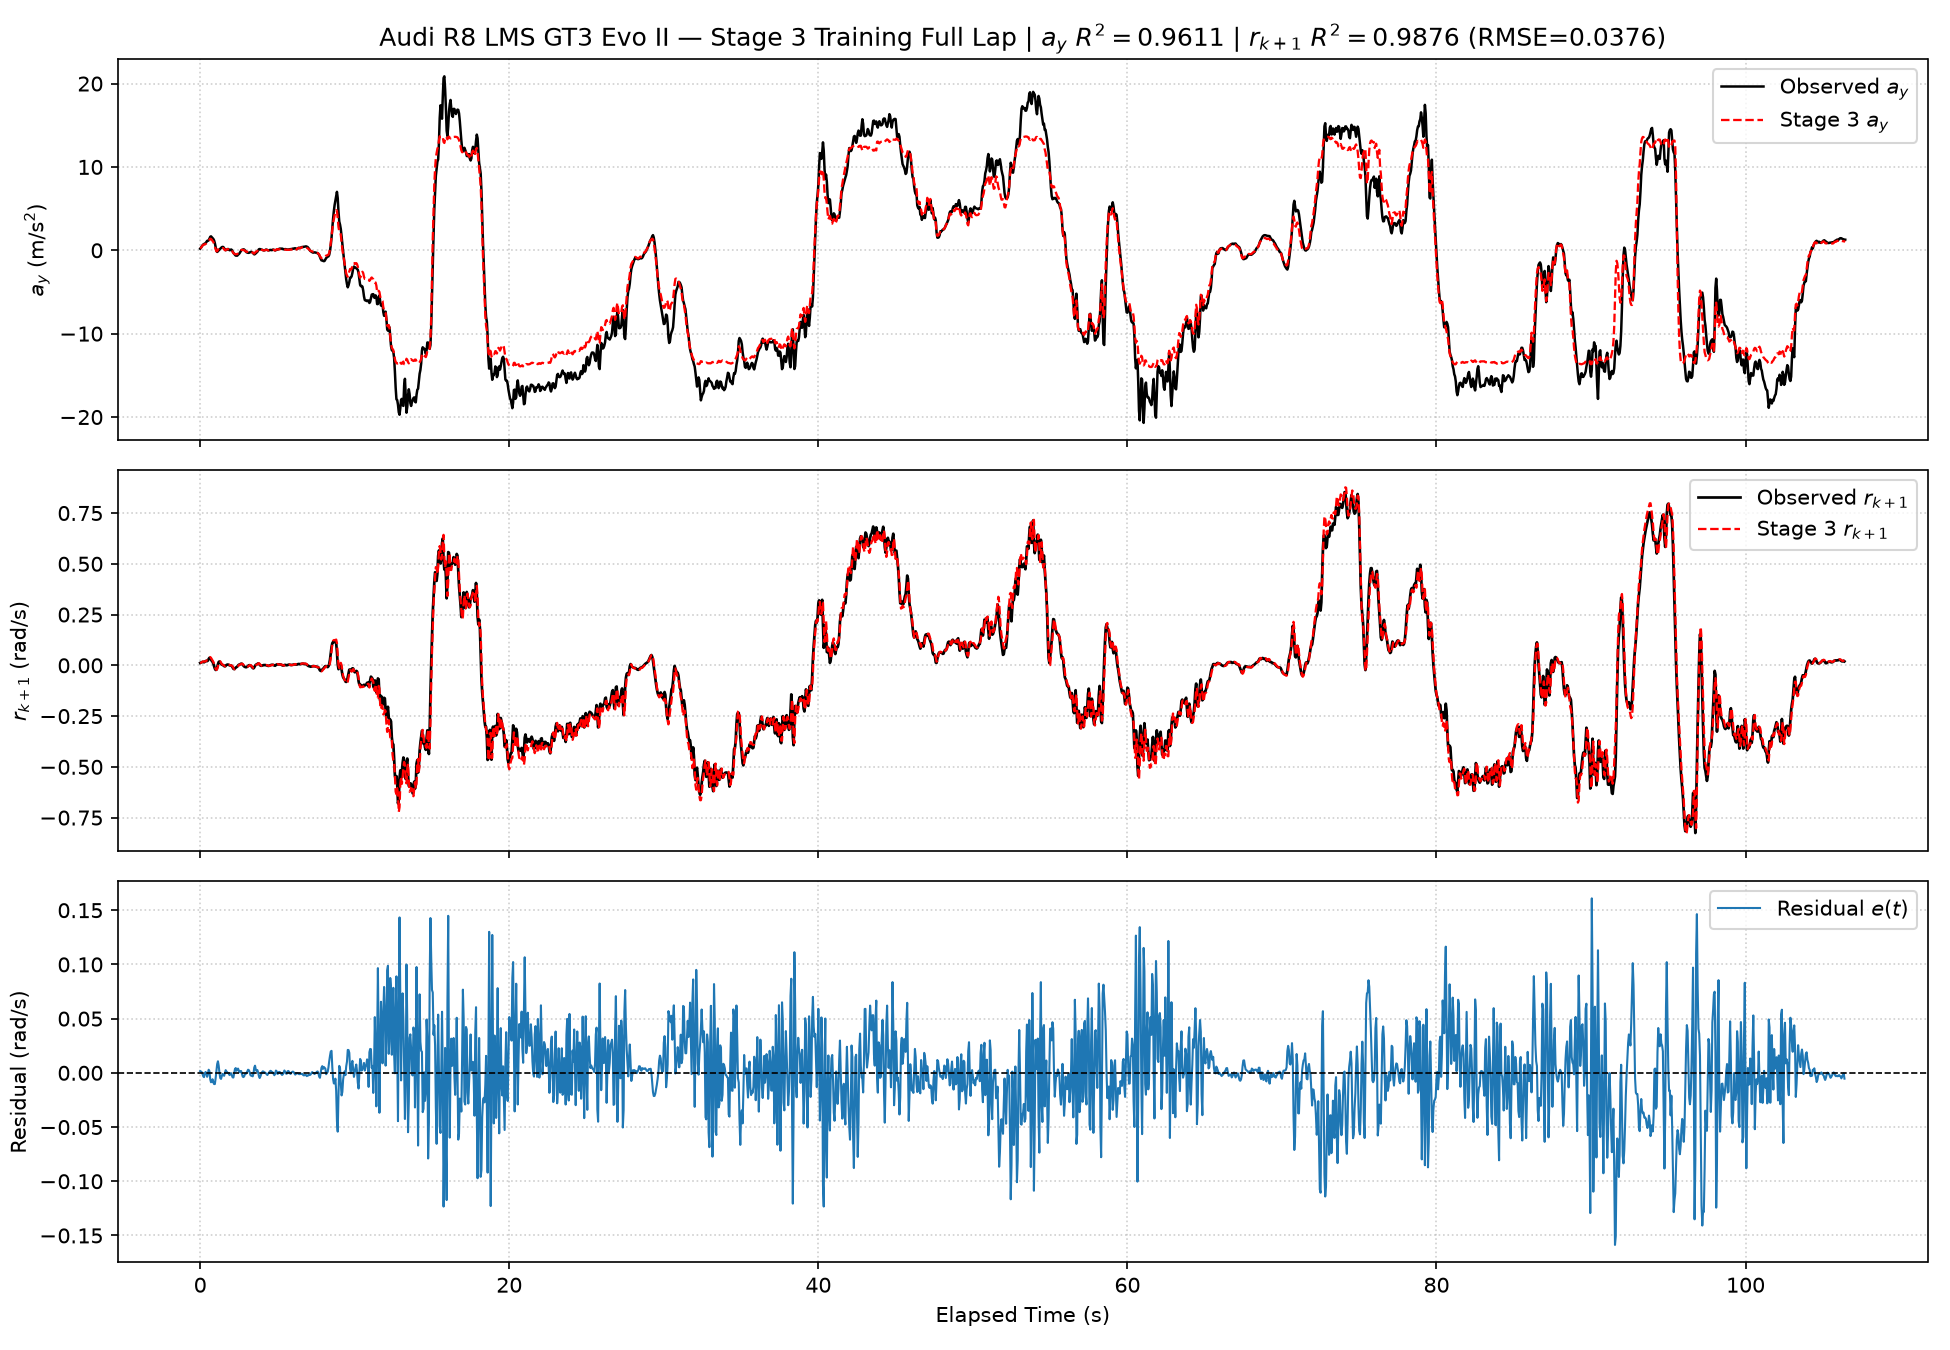

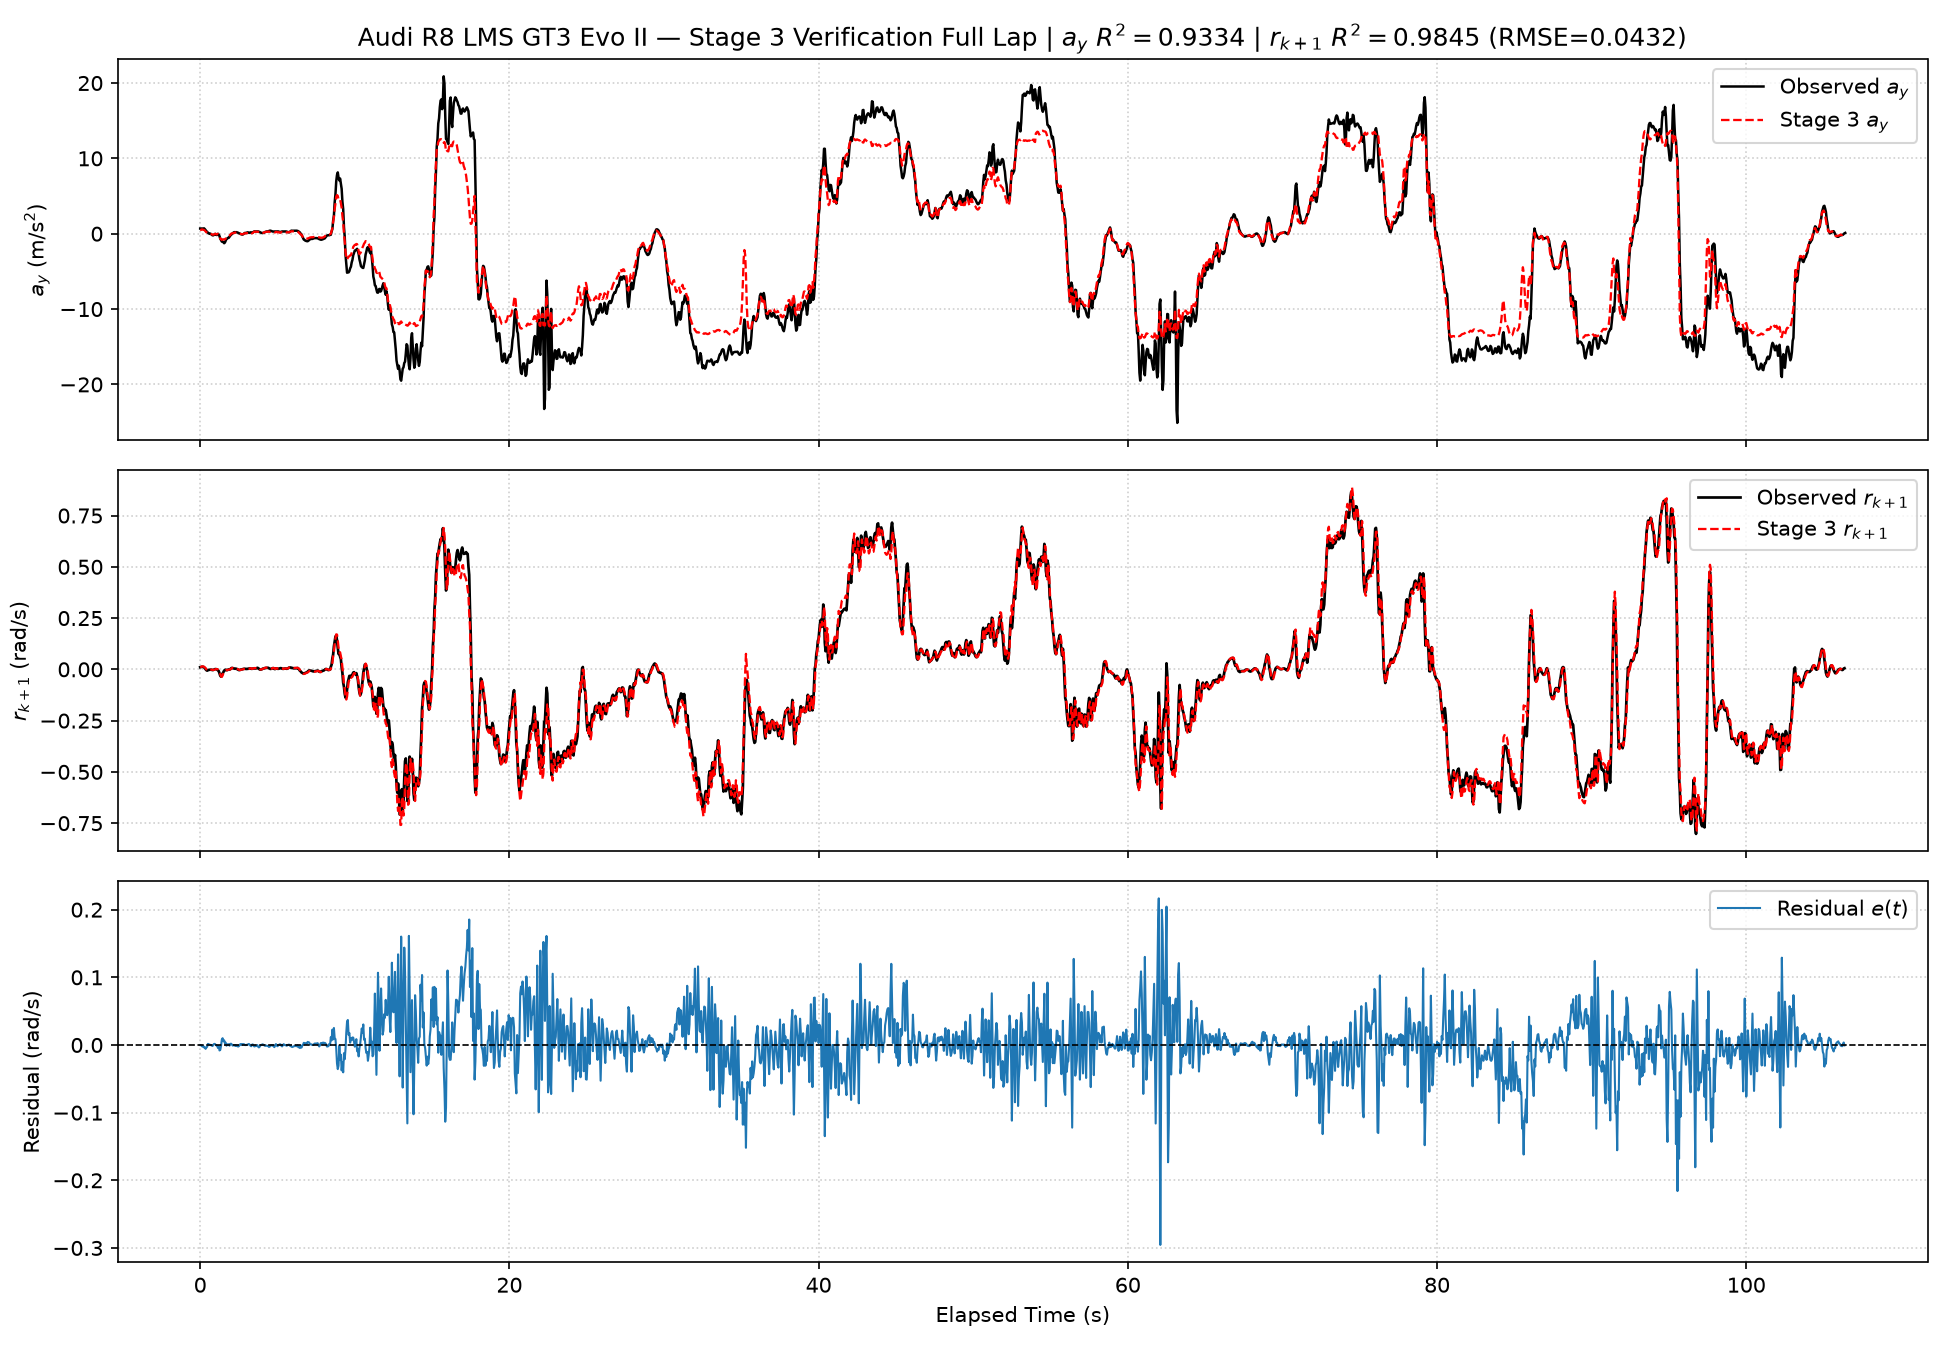

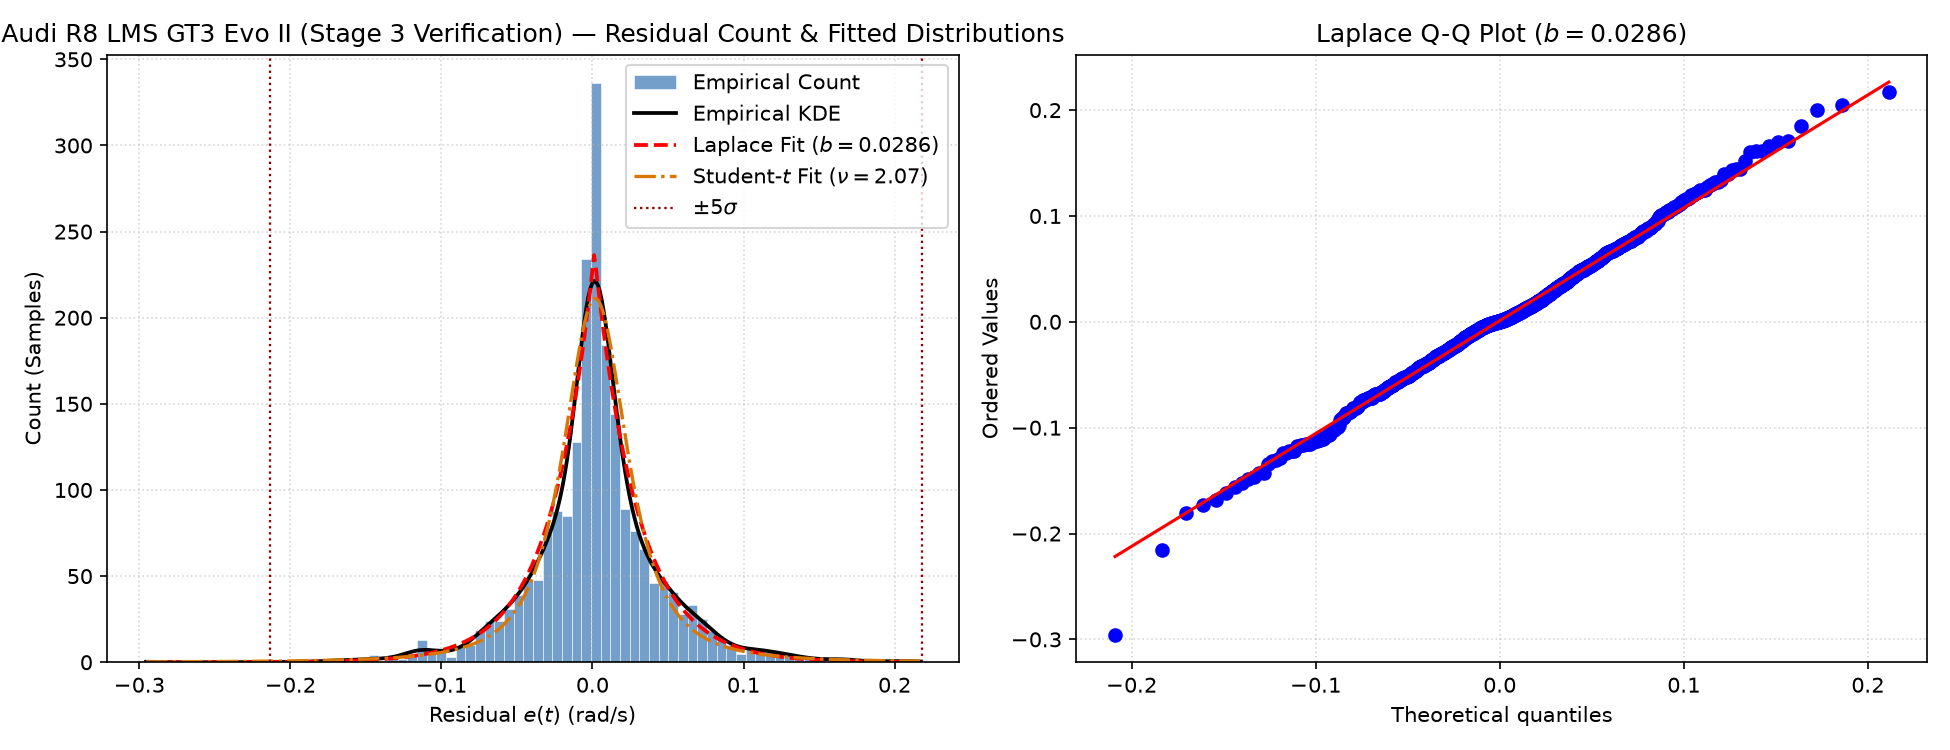

In [5]:
# Plot 2: Lateral Acceleration & Next-Step Yaw Rate Fit (Training + Verification)
def plot_stage3_fit(df, sim_res, title, save_path):
    t_full = df["Time"].to_numpy() - float(df["Time"].iloc[0])
    t_k1 = t_full[:-1]
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    ax1.plot(t_full, sim_res.eval_ay.y_true, "k-", lw=1.2, label=r"Observed $a_y$")
    ax1.plot(t_full, sim_res.eval_ay.y_pred, "r--", lw=1.1, label=r"Stage 3 $a_y$")
    ax1.set_ylabel(r"$a_y$ ($\mathrm{m/s^2}$)")
    ax1.set_title(f"{title} | $a_y$ $R^2={sim_res.eval_ay.r2:.4f}$ | $r_{{k+1}}$ $R^2={sim_res.eval_r_next.r2:.4f}$ (RMSE={sim_res.eval_r_next.rmse:.4f})")
    ax1.grid(True, ls=":", alpha=0.6)
    ax1.legend(loc="upper right")

    ax2.plot(t_k1, sim_res.eval_r_next.y_true, "k-", lw=1.3, label=r"Observed $r_{k+1}$")
    ax2.plot(t_k1, sim_res.eval_r_next.y_pred, "r--", lw=1.1, label=r"Stage 3 $r_{k+1}$")
    ax2.set_ylabel(r"$r_{k+1}$ ($\mathrm{rad/s}$)")
    ax2.grid(True, ls=":", alpha=0.6)
    ax2.legend(loc="upper right")

    ax3.plot(t_k1, sim_res.eval_r_next.residuals, color="#1f77b4", lw=1.0, label=r"Residual $e(t)$")
    ax3.axhline(0.0, color="k", ls="--", lw=0.8)
    ax3.set_xlabel("Elapsed Time (s)")
    ax3.set_ylabel(r"Residual ($\mathrm{rad/s}$)")
    ax3.grid(True, ls=":", alpha=0.6)
    ax3.legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.close(fig)
    return save_path

p_tr = plot_stage3_fit(df_tr, train_res, f"{cfg.vehicle} — Stage 3 Training Full Lap", out_dir / "full_lap_train.png")
p_va = plot_stage3_fit(df_va, ver_res, f"{cfg.vehicle} — Stage 3 Verification Full Lap", out_dir / "full_lap_verification.png")
p_dist = plot_residual_distribution(ver_res.eval_r_next, f"{cfg.vehicle} (Stage 3 Verification)", out_dir / "verif_residuals_dist.png")

for img in [p_tr, p_va, p_dist]:
    display(Image(filename=str(img)))

## 3. Corner-Specific Verification & Stage 2 vs. Stage 3 Benchmark

In [6]:
corner_specs = [
    ("T3 (Renault)", 850.0, 1450.0, 0.9834, 0.9771),
    ("T4 (Repsol)", 1450.0, 1850.0, 0.9808, 0.9691),
    ("T5 (Seat)", 1850.0, 2250.0, 0.9875, 0.9866),
    ("T13–T14–T15 Complex", 3950.0, 4450.0, 0.9803, 0.9748),
]

rows = [{
    "Segment": "Full Lap",
    "Stage 2 Verif R2 (r_k+1)": 0.9829,
    "Stage 3 Train R2 (ay)": round(train_res.eval_ay.r2, 4),
    "Stage 3 Verif R2 (ay)": round(ver_res.eval_ay.r2, 4),
    "Stage 3 Train R2 (r_k+1)": round(train_res.eval_r_next.r2, 4),
    "Stage 3 Verif R2 (r_k+1)": round(ver_res.eval_r_next.r2, 4),
    "Stage 3 Verif RMSE (rad/s)": round(ver_res.eval_r_next.rmse, 4),
}]

for label, s_m, e_m, s2_tr, s2_va in corner_specs:
    sub_tr = df_tr[(df_tr["LAP_DIST_M"] >= s_m) & (df_tr["LAP_DIST_M"] <= e_m)].reset_index(drop=True)
    sub_va = df_va[(df_va["LAP_DIST_M"] >= s_m) & (df_va["LAP_DIST_M"] <= e_m)].reset_index(drop=True)
    c_tr = model.evaluate(sub_tr)
    c_va = model.evaluate(sub_va)
    rows.append({
        "Segment": label,
        "Stage 2 Verif R2 (r_k+1)": s2_va,
        "Stage 3 Train R2 (ay)": round(c_tr.eval_ay.r2, 4),
        "Stage 3 Verif R2 (ay)": round(c_va.eval_ay.r2, 4),
        "Stage 3 Train R2 (r_k+1)": round(c_tr.eval_r_next.r2, 4),
        "Stage 3 Verif R2 (r_k+1)": round(c_va.eval_r_next.r2, 4),
        "Stage 3 Verif RMSE (rad/s)": round(c_va.eval_r_next.rmse, 4),
    })

bench_df = pd.DataFrame(rows)
display(Markdown("### Stage 2 (Discrete SINDy) vs. Stage 3 (4-Wheel Physics)"))
display(bench_df)

with open(out_dir / "report.json", "w", encoding="utf-8") as f:
    json.dump({
        "experiment": cfg.experiment_name,
        "params": model.params.to_dict(),
        "benchmark": rows,
    }, f, indent=2)

### Stage 2 (Discrete SINDy) vs. Stage 3 (4-Wheel Physics)

,Segment,Stage 2 Verif R2 (r_k+1),Stage 3 Train R2 (ay),Stage 3 Verif R2 (ay),Stage 3 Train R2 (r_k+1),Stage 3 Verif R2 (r_k+1),Stage 3 Verif RMSE (rad/s)
0,Full Lap,0.9829,0.9611,0.9334,0.9876,0.9845,0.0432
1,T3 (Renault),0.9771,0.9461,0.8486,0.9828,0.9734,0.0554
2,T4 (Repsol),0.9691,0.9062,0.7499,0.9774,0.9631,0.0429
3,T5 (Seat),0.9866,0.9765,0.9538,0.9873,0.9858,0.0391
4,T13–T14–T15 Complex,0.9748,0.9246,0.9327,0.9840,0.9867,0.0493
